<a href="https://colab.research.google.com/github/tanay2405/AutoLens/blob/main/Decision_Trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup and data

In [22]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, recall_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED = "#1f5fbf", "#d62728"

**The data.** UCI Heart Disease, Cleveland clinic: 303 patients, 13 clinical measurements. The original label `num` runs from 0 (no disease) to 4. We turn it into a yes/no diagnosis: `num > 0` means heart disease.

The CSVs have already been preprocessed. We will look at how to do this in the next module.

In [23]:
train_loaded = pd.read_csv("train_preprocessed.csv")
test_loaded = pd.read_csv("test_preprocessed.csv")

X_train = train_loaded.drop(columns=['target'])
y_train = train_loaded['target'].values

X_test = test_loaded.drop(columns=['target'])
y_test = test_loaded['target'].values

print("Loaded X_train, X_test, y_train, and y_test from preprocessed CSVs.")
print("X_train shape:", X_train.shape, "  y_train shape:", y_train.shape)

Loaded X_train, X_test, y_train, and y_test from preprocessed CSVs.
X_train shape: (227, 22)   y_train shape: (227,)


In [24]:
X_train

,cp_1.0,cp_2.0,cp_3.0,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,...,thal_7.0,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,55.0,0.0,132.0,342.0,0.0,166.0,0.0,1.2,0.0
1,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,62.0,0.0,140.0,394.0,0.0,157.0,0.0,1.2,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,59.0,1.0,164.0,176.0,1.0,90.0,0.0,1.0,2.0
3,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,51.0,1.0,94.0,227.0,0.0,154.0,1.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,64.0,1.0,110.0,211.0,0.0,144.0,1.0,1.8,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
222,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,43.0,1.0,130.0,315.0,0.0,162.0,0.0,1.9,1.0
223,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,63.0,0.0,124.0,197.0,0.0,136.0,1.0,0.0,0.0
224,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,1.0,57.0,1.0,128.0,229.0,0.0,150.0,0.0,0.4,1.0
225,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0


## 2. Entropy and information gain by hand

$$H(S) = -\sum_k p_k \log_2 p_k \qquad\qquad \mathrm{IG} = H(\mathrm{parent}) - \sum_j \frac{n_j}{n}\, H(\mathrm{child}_j)$$

Entropy is 0 for a pure node and 1 bit for a 50/50 node (two classes). A good split leaves purer children, so it has a large information gain.

In [25]:
def entropy(counts):
    counts = np.asarray(counts, dtype=float)
    counts = counts[counts > 0]
    p = counts / counts.sum()
    return -(p * np.log2(p)).sum() + 0.0          # + 0.0 turns -0.0 into 0.0

def info_gain(parent_counts, children_counts):
    n = sum(sum(c) for c in children_counts)
    remainder = sum(sum(c) / n * entropy(c) for c in children_counts)
    return entropy(parent_counts) - remainder

print("pure node        :", entropy([10, 0]))
print("8 vs 2           :", round(entropy([8, 2]), 3))
print("50 / 50          :", entropy([5, 5]))

pure node        : 0.0
8 vs 2           : 0.722
50 / 50          : 1.0


### 2a. Warm-up: play tennis (14 days)

In [26]:
tennis = pd.read_csv("play_tennis.csv", index_col=0)
tennis

,outlook,temp,humidity,wind,play
index,,,,,
0,sunny,hot,high,False,no
1,sunny,hot,high,True,no
2,overcast,hot,high,False,yes
3,rainy,mild,high,False,yes
4,rainy,cool,normal,False,yes
5,rainy,cool,normal,True,no
6,overcast,cool,normal,True,yes
7,sunny,mild,high,False,no
8,sunny,cool,normal,False,yes


In [27]:
print("Root: play =", tennis.play.value_counts().to_dict(), "  entropy = %.3f" % entropy(tennis.play.value_counts().values))

def gain_for(frame, col, target="play"):
    parent = [int((frame[target] == "yes").sum()), int((frame[target] == "no").sum())]
    kids = [[int((g[target] == "yes").sum()), int((g[target] == "no").sum())] for _, g in frame.groupby(col)]
    return info_gain(parent, kids), dict(zip(sorted(frame[col].unique()), kids))

for col in ["outlook", "temp", "humidity", "wind"]:
    g, kids = gain_for(tennis, col)
    print(f"{col:9s} IG = {g:.3f}   [yes, no] per value: {kids}")

Root: play = {'yes': 9, 'no': 5}   entropy = 0.940
outlook   IG = 0.247   [yes, no] per value: {'overcast': [4, 0], 'rainy': [3, 2], 'sunny': [2, 3]}
temp      IG = 0.029   [yes, no] per value: {'cool': [3, 1], 'hot': [2, 2], 'mild': [4, 2]}
humidity  IG = 0.152   [yes, no] per value: {'high': [3, 4], 'normal': [6, 1]}
wind      IG = 0.048   [yes, no] per value: {np.False_: [6, 2], np.True_: [3, 3]}


**Your turn.** Which attribute becomes the root? Overcast days are all "yes". What does that do to the entropy of that child?
Then pick the sunny branch only (`tennis[tennis.outlook == "sunny"]`) and rerun `gain_for` for the remaining attributes. Which one wins there?

The outlook attribute becomes the root because it has the highest IG of 0.247. The overcast days are all "yes" which means that the entropy of that child will be 0. After picking sunny branch and rerunning "gain_for" for the remaining attributes, the humidity attribute wins because the 5 days are split into two groups and it has a gain of 0.971.

In [28]:
sunny = tennis[tennis.outlook == "sunny"]
for col in ["temp", "humidity", "wind"]:
    print(col, round(gain_for(sunny, col)[0], 3))

temp 0.571
humidity 0.971
wind 0.02


### 2b. Heart disease: split on chest pain type

Chest pain type is categorical and clinically meaningful. Count the training patients in each of its four groups.

In [29]:
cp_names = {1: "typical angina", 2: "atypical angina", 3: "non-anginal", 4: "asymptomatic"}
rows = []
for code_, name in cp_names.items():
    col_name = f"cp_{code_}.0"
    m = (X_train[col_name] == 1.0).values
    rows.append({"cp": name, "patients": m.sum(), "healthy": (y_train[m] == 0).sum(), "disease": (y_train[m] == 1).sum(),
                 "entropy": round(entropy([(y_train[m] == 0).sum(), (y_train[m] == 1).sum()]), 3)})
cp_table = pd.DataFrame(rows)
print("root counts [healthy, disease]:", [int((y_train == 0).sum()), int((y_train == 1).sum())], "  entropy = %.3f" % entropy([(y_train == 0).sum(), (y_train == 1).sum()]))
cp_table

root counts [healthy, disease]: [123, 104]   entropy = 0.995


,cp,patients,healthy,disease,entropy
0,typical angina,18,12,6,0.918
1,atypical angina,39,32,7,0.679
2,non-anginal,56,43,13,0.782
3,asymptomatic,114,36,78,0.900


In [30]:
parent = [(y_train == 0).sum(), (y_train == 1).sum()]
kids = cp_table[["healthy", "disease"]].values.tolist()
print("Information gain of a 4-way split on cp: %.3f bits" % info_gain(parent, kids))

# Corrected: use the one-hot encoded column 'cp_4.0' instead of 'cp'
m4 = (X_train["cp_4.0"] == 1.0).values
kids2 = [[(y_train[m4] == 0).sum(), (y_train[m4] == 1).sum()], [(y_train[~m4] == 0).sum(), (y_train[~m4] == 1).sum()]]
print("Information gain of 'asymptomatic or not': %.3f bits" % info_gain(parent, kids2))

Information gain of a 4-way split on cp: 0.161 bits
Information gain of 'asymptomatic or not': 0.156 bits


**Discuss.** In the 4-way table, which group is nearly pure? Which groups are close to 50/50? What would a clinician say about the asymptomatic group?

In the 4-way table, the atypical angina is the closest group to being pure because it;s 82% healthy and entropy of 0.679. The other groups have a lower percentage of being healthy and higher percentage of disease making them less pure.

In [31]:
# Define FEATURES and ensure we use X_train consistently
FEATURES = X_train.columns.tolist()

# A fair comparison: the best yes/no split for EVERY column, the way sklearn searches.
def best_binary_gain(col):
    x = X_train[col].values
    cuts = (np.unique(x)[:-1] + np.unique(x)[1:]) / 2
    best = (0.0, None)
    for t in cuts:
        left = x <= t
        kids = [[(y_train[left] == 0).sum(), (y_train[left] == 1).sum()], [(y_train[~left] == 0).sum(), (y_train[~left] == 1).sum()]]
        g = info_gain(parent, kids)
        if g > best[0]: best = (g, t)
    return best

gains = pd.DataFrame({c: best_binary_gain(c) for c in FEATURES}, index=["info_gain", "threshold"]).T.sort_values("info_gain", ascending=False)
gains.head(8)

,info_gain,threshold
thal_3.0,0.203893,0.5
ca,0.181928,0.5
thal_7.0,0.169133,0.5
cp_4.0,0.155718,0.5
oldpeak,0.129330,1.7
slope_1.0,0.125482,0.5
exang,0.123609,0.5
thalach,0.120957,147.5


**Discuss.** Which feature has the largest gain? Is it the chest pain feature we chose? Write down the feature and the threshold. Check it against sklearn in the next section.

The thal_3.0 has the largest gain of 0.204 with the threshold of 0.5. This means that it's not the chest pain feature we chose.

## 3. Let sklearn grow the tree

`DecisionTreeClassifier(criterion="entropy")` tries every feature and every threshold at every node, exactly as in the table above. It keeps the split with the largest gain and recurses.

In [32]:
# Use X_train directly instead of A_train to build the tree
tree3 = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=0).fit(X_train, y_train)

root = tree3.tree_.feature[0]
print("sklearn root:", FEATURES[root], "<=", tree3.tree_.threshold[0])
print("hand-computed best:", gains.index[0], "<=", gains.iloc[0, 1])
print()
print(export_text(tree3, feature_names=FEATURES, show_weights=True))

sklearn root: thal_3.0 <= 0.5
hand-computed best: thal_3.0 <= 0.5

|--- thal_3.0 <= 0.50
|   |--- cp_4.0 <= 0.50
|   |   |--- thalach <= 143.00
|   |   |   |--- weights: [2.00, 7.00] class: 1
|   |   |--- thalach >  143.00
|   |   |   |--- weights: [16.00, 7.00] class: 0
|   |--- cp_4.0 >  0.50
|   |   |--- oldpeak <= 0.55
|   |   |   |--- weights: [6.00, 8.00] class: 1
|   |   |--- oldpeak >  0.55
|   |   |   |--- weights: [1.00, 53.00] class: 1
|--- thal_3.0 >  0.50
|   |--- ca <= 0.50
|   |   |--- age <= 57.50
|   |   |   |--- weights: [60.00, 1.00] class: 0
|   |   |--- age >  57.50
|   |   |   |--- weights: [20.00, 8.00] class: 0
|   |--- ca >  0.50
|   |   |--- cp_4.0 <= 0.50
|   |   |   |--- weights: [15.00, 7.00] class: 0
|   |   |--- cp_4.0 >  0.50
|   |   |   |--- weights: [3.00, 13.00] class: 1



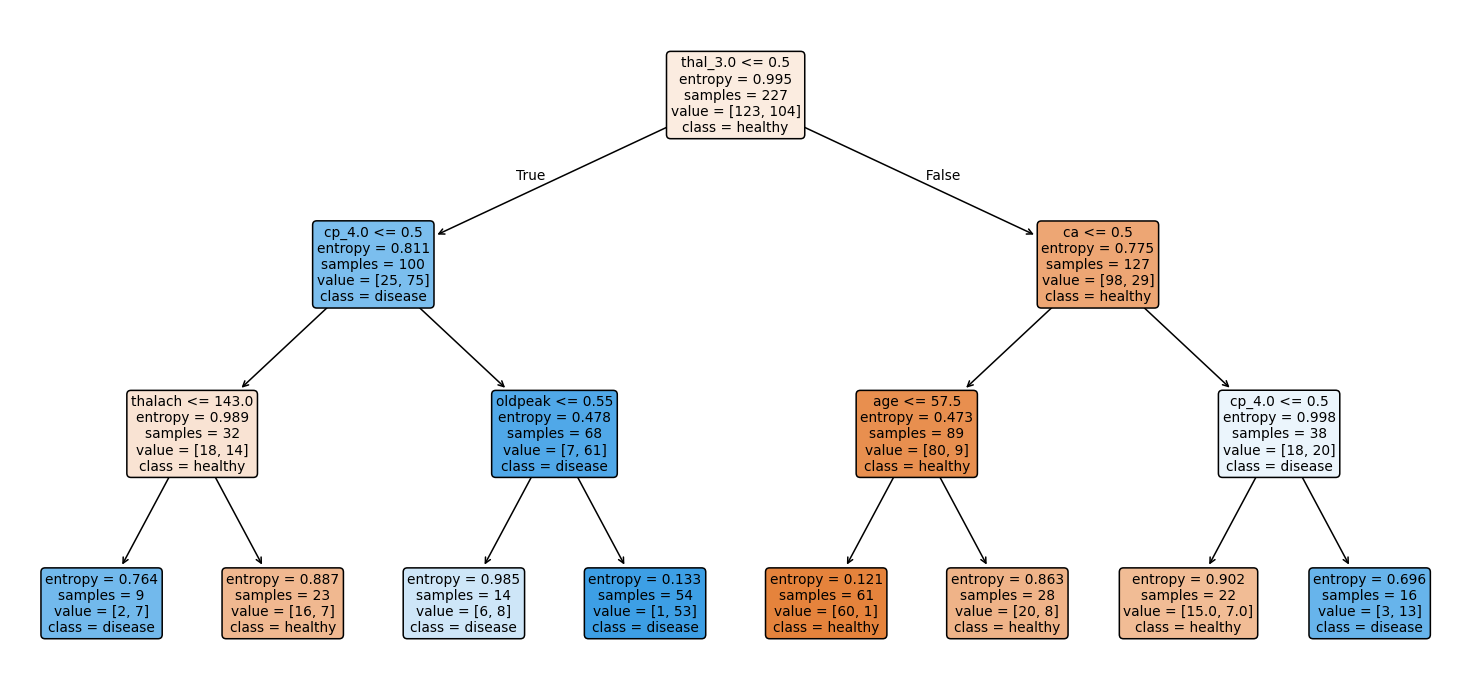

In [33]:
fig, ax = plt.subplots(figsize=(17, 8))
plot_tree(tree3, feature_names=FEATURES, class_names=["healthy", "disease"], filled=True, rounded=True, fontsize=9, ax=ax, impurity=True)
plt.show()

Read the tree as a list of questions. Left is "yes", right is "no". Each box shows the entropy, the number of patients, the counts `[healthy, disease]`, and the majority class.

**Discuss.** Trace one test patient from the root to a leaf. Does the root match your hand calculation? If two features have the same gain, which does sklearn pick?

The skrlearn root "thal_3.0 <- 0.5" matches my hand calculation since both end up checking to see which feature and threshold has the highest gain. If two features have the same gain, sklearn will just pick the one that was analyzed first.

In [34]:
def report(model, A, y_true, name):
    pred = model.predict(A)
    cm = confusion_matrix(y_true, pred)
    print(f"{name}: accuracy {np.mean(pred == y_true):.3f}   recall (sick patients found) {recall_score(y_true, pred):.3f}")
    print(pd.DataFrame(cm, index=["actual healthy", "actual disease"], columns=["pred healthy", "pred disease"]))
    print()

# Corrected: Use X_train and X_test instead of A_train and A_test
report(tree3, X_train, y_train, "depth-3 tree, train")
report(tree3, X_test, y_test, "depth-3 tree, test ")

depth-3 tree, train: accuracy 0.846   recall (sick patients found) 0.779
                pred healthy  pred disease
actual healthy           111            12
actual disease            23            81

depth-3 tree, test : accuracy 0.842   recall (sick patients found) 0.743
                pred healthy  pred disease
actual healthy            38             3
actual disease             9            26



**Discuss.** A false negative is a sick patient sent home. A false positive is a healthy patient sent for more tests. Which error costs more here? Which number above tells you about it?

A false negative costs more because this means a sick patient has to be sent home without receiving any treatment which can be dangerous for that patient. The recall number tells us about it because it tells the number of sick pateints that were found which informs about the missing patients too.

## 4. Depth: lower training error, higher variance

Each extra level of depth splits the data into smaller groups. A deep tree can memorize the training set. We sweep `max_depth` and measure training accuracy and **cross-validation** accuracy on the training set. The test set stays untouched.

In [16]:
cv5x5 = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
def make_tree(**kw): return Pipeline([("tree", DecisionTreeClassifier(criterion="entropy", random_state=0, **kw))])

rows = []
for d in range(1, 13):
    cv = cross_val_score(make_tree(max_depth=d), X_train, y_train, cv=cv5x5)
    fit = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0).fit(X_train, y_train)
    rows.append({"max_depth": d, "leaves": fit.get_n_leaves(), "train_acc": fit.score(X_train, y_train), "cv_acc": cv.mean()})
depth_table = pd.DataFrame(rows)
depth_table.round(3)

,max_depth,leaves,train_acc,cv_acc
0,1,2,0.762,0.733
1,2,4,0.789,0.749
2,3,8,0.846,0.745
3,4,16,0.868,0.731
4,5,24,0.912,0.724
5,6,30,0.943,0.700
6,7,35,0.974,0.699
7,8,37,0.982,0.696
8,9,38,0.987,0.700
9,10,39,0.987,0.697


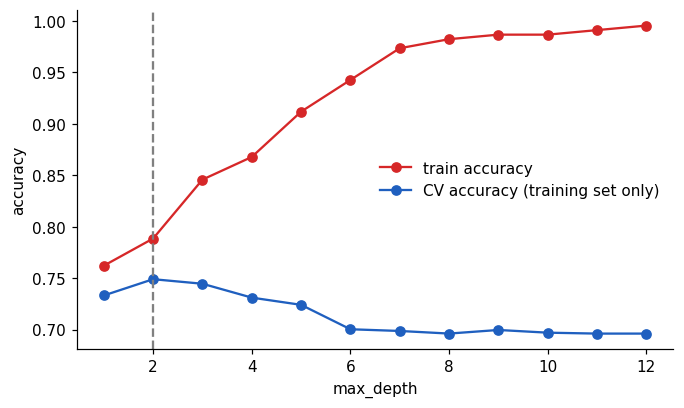

best depth by CV: 2


In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depth_table.max_depth, depth_table.train_acc, "-o", color=RED, label="train accuracy")
ax.plot(depth_table.max_depth, depth_table.cv_acc, "-o", color=BLUE, label="CV accuracy (training set only)")
best_d = int(depth_table.loc[depth_table.cv_acc.idxmax(), "max_depth"])
ax.axvline(best_d, color="gray", ls="--"); ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.legend(frameon=False)
plt.show()
print("best depth by CV:", best_d)

**Discuss.** At which depth does training accuracy reach 1.0? What does the gap between the two curves tell you about bias and variance? Why can we not choose the depth from the training curve?

The training accuracy never reaches 1.0 as it only reaches 0.996 at depth 12. The gap between the two curves is growing because as depth increases, the training accuracy will rise while the CV accuracy will drop. This gap represent variance since the deep trees are focused on memorizing the training data rather than understanding the pattern. Shallow trees have high bias since both the training accuracy and CV accuracy will stay low as the model is too simple.

### Decision regions with two features

To *see* what depth does, fit trees on just `thalach` (max heart rate) and `oldpeak` (ST depression). Every region is a rectangle, because every split is a threshold on one feature.

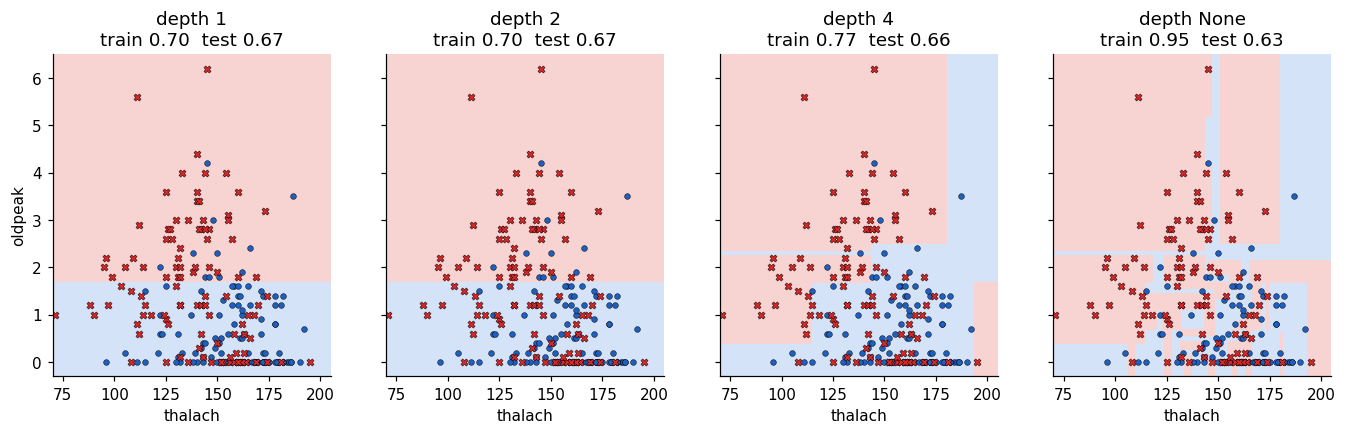

In [18]:
two = ["thalach", "oldpeak"]
Z_tr, Z_te = X_train[two].values, X_test[two].values
g1, g2 = np.meshgrid(np.linspace(70, 205, 300), np.linspace(-0.3, 6.5, 300))
grid = np.column_stack([g1.ravel(), g2.ravel()])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, d in zip(axes, [1, 2, 4, None]):
    m = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0).fit(Z_tr, y_train)
    ax.contourf(g1, g2, m.predict(grid).reshape(g1.shape), levels=[-0.5, 0.5, 1.5], colors=["#d4e3f7", "#f7d4d2"])
    ax.scatter(*Z_tr[y_train == 0].T, c=BLUE, s=14, edgecolor="k", lw=0.3)
    ax.scatter(*Z_tr[y_train == 1].T, c=RED, marker="X", s=22, edgecolor="k", lw=0.3)
    ax.set_title(f"depth {d}\ntrain {m.score(Z_tr, y_train):.2f}  test {m.score(Z_te, y_test):.2f}")
    ax.set_xlabel("thalach")
axes[0].set_ylabel("oldpeak")
plt.show()

### Choose depth and leaf size with cross-validation

Depth is one knob. `min_samples_leaf` is another: it forbids leaves with only a handful of patients. A grid search tries every pair with cross-validation on the training set, then refits the best pair on all of the training set.

In [19]:
grid_search = GridSearchCV(make_tree(), {"tree__max_depth": [2, 3, 4, 5, 6, None], "tree__min_samples_leaf": [1, 3, 5, 10, 20]},
                           cv=cv5x5, n_jobs=-1).fit(X_train, y_train)

results = pd.DataFrame(grid_search.cv_results_)
heat = results.pivot_table(index=results.param_tree__max_depth.astype(str), columns="param_tree__min_samples_leaf", values="mean_test_score")
print("best:", grid_search.best_params_, "  CV accuracy %.3f" % grid_search.best_score_)
heat.round(3)

best: {'tree__max_depth': 4, 'tree__min_samples_leaf': 10}   CV accuracy 0.768


param_tree__min_samples_leaf,1,3,5,10,20
param_tree__max_depth,,,,,
2,0.749,0.749,0.749,0.752,0.752
3,0.745,0.745,0.744,0.768,0.751
4,0.731,0.732,0.733,0.768,0.751
5,0.724,0.724,0.720,0.768,0.751
6,0.700,0.721,0.713,0.768,0.751
None,0.696,0.725,0.713,0.768,0.751


In [20]:
best_tree = grid_search.best_estimator_
print("Test set, used once:")
pred = best_tree.predict(X_test)
print("accuracy %.3f   recall %.3f" % (np.mean(pred == y_test), recall_score(y_test, pred)))
print(confusion_matrix(y_test, pred))

Test set, used once:
accuracy 0.855   recall 0.771
[[38  3]
 [ 8 27]]


**Discuss.** The test set has only 76 patients, so one extra mistake moves accuracy by 1.3 points. Why is it risky to pick the final model by looking at this number? What would you report to the hospital?

It's risky to pick the final model by picking this number because 76 patients is a small sample size and if we choose that model, it won't perform well on new data. I would report the CV accuracy to the hopsital alongside the test result and recall number because each of these metrics provide information that can be reliable when the model has to perform on new patients.

## 5. One tree is unstable

Retrain on a different resample of the same 227 patients and the tree can change a lot. High variance means the answer depends on which patients happened to be in the sample.

In [21]:
rng = np.random.RandomState(0)
roots, accs = {}, []
for _ in range(40):
    idx = rng.randint(0, len(X_train), len(X_train))              # a bootstrap sample: draw N rows with replacement
    t = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=0).fit(X_train.iloc[idx], y_train[idx])
    f = FEATURES[t.tree_.feature[0]]
    roots[f] = roots.get(f, 0) + 1
    accs.append(t.score(X_test, y_test))
print("root feature across 40 resamples:", roots)
print("test accuracy: mean %.3f, std %.3f, min %.3f, max %.3f" % (np.mean(accs), np.std(accs), np.min(accs), np.max(accs)))

root feature across 40 resamples: {'cp_4.0': 5, 'thal_3.0': 20, 'ca': 10, 'thal_7.0': 2, 'exang': 2, 'slope_1.0': 1}
test accuracy: mean 0.772, std 0.041, min 0.697, max 0.855


**Discuss.** The root changes between resamples. Is that a sign that the data has no signal, or that several features carry similar signal?

This isn't a sign that the data has no signal, but several features do carry a similar signal which does mean that the root will change between resamples. That's why it's important to average many trees to understand the data better.